# 感度分析① スケーリングパラメータ (a2, b1)

名目速度関数(C-C, T-T)は固定し、a2・b1だけを対数格子 [0.25, 4] で動かして u*, p1*, p2*, s を調べる。

- データ準備・Eq.7・p* はすべて `whole_pipeline` の関数を使う（`run_pipeline` の Step 3 と同じスナップショット）
- 単位: 密度 veh/km/lane、速度 km/h（a2, b1, p*, s は無次元）
- inverted(a2, b1) = printed(1/a2, 1/b1) なので、スイープは printed だけで足りる

In [6]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

sys.path.append(os.path.abspath('..'))
from src.whole_pipeline import prepare_data
from src.sensitivity_scaling import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# 名目速度関数（km単位）
params = {
    'paper': ({'ub': 12.762, 'uf': 118.367, 'rhoc': 12.676, 'theta1': 4.995, 'theta2': 0.2309},
              {'uf': 68.478, 'rhoc': 25.936}),
    'own':   ({'ub': 12.760, 'uf': 118.369, 'rhoc': 12.676, 'theta1': 4.999, 'theta2': 0.343},
              {'uf': 68.473, 'rhoc': 18.542}),   # strong_constraint
}
# 図に印を付ける (a2, b1)
marks = {'paper': (0.4528, 2.5996), 'own': (0.4687, 1.8331)}

SKIP_WARMUP, SKIP_COOLDOWN = 100, 100   # run_pipeline の既定値と同じ

In [3]:
data = prepare_data()   # 1回だけ実行

(4566387, 19)

--フリッカリング除去--
補正されたブロック数: 671
行数: 4,566,387

--フリッカリング除去--
補正されたブロック数: 142
行数: 4,566,387

--フリッカリング補正行の車間距離を座標から再計算--
対象行: 3,225  再計算できた行: 2,472  NaNにした行: 753
  NaNの内訳: 先行車が別車線 345行 / 先行車なし・位置不明・距離0以下 408行
  元の値から1ft超変わった行: 2,284  (元の値が0だった行: 208)

--ペアIDを付与--
総行数: 4,566,387
追従ペア数: 13,827

--モードID別を付与--
総行数: 4,566,387
追従ペア数: 13,827
mode_id
1.0    12337
2.0      438
3.0      549
4.0       42
5.0      461
dtype: int64

--追従していない軌跡データを削除--
フィルタ前の行数: 4,566,387
フィルタ後の行数: 4,359,245
除外された行数: 207,142
ペア数: 13,827

--車線フィルタ(2,3,4レーンを残す)--
フィルタ前: 4,359,245行
フィルタ後: 2,338,830行
除外された行数: 2,020,415行
追従ペア数: 5,780

車線の分布:
Lane_ID
2.0    800339
3.0    689350
4.0    849141
Name: count, dtype: int64

--車種フィルタ(1,2,3,4の追従モードを残す)--
フィルタ前のペア数: 5,780
フィルタ後のペア数: 5,666
除外されたペア数: 114
フィルタ後行数: 2,335,438行

モードID別ペア数:
mode_id
1.0    5067
2.0     237
3.0     326
4.0      36
dtype: int64

--追従時間フィルタ--
フィルタ前のペア数: 5,666
フィルタ後のペア数: 1,570
除外されたペア数: 4,096
フィルタ前の行数: 2,335,438
フィルタ後の行数: 1,487,854

--カットオフウィンドウ-

### パイプラインとの一致確認
brentq版(`pipeline_step3`)と二分法版(`surplus_at`)で u*, p1*, p2*, s が一致することを、格子の四隅・論文値・自分の推定値で確認する。一致しなければ AssertionError で止まる。

In [4]:
ab_check = [marks['paper'], marks['own'], (1.0, 1.0),
            (0.25, 0.25), (4.0, 4.0), (0.25, 4.0), (4.0, 0.25)]
for name, (car, trk) in params.items():
    for scaling in ['printed', 'inverted']:
        check_against_pipeline(data, car, trk, scaling, ab_check,
                               skip_sec_warmup=SKIP_WARMUP, skip_sec_cooldown=SKIP_COOLDOWN)

各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件
1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 30件）
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件
1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 3,543件）
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件
1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 2,130件）
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件
1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 4,989件）
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,

### スイープ
観測状態(rho1, rho2)は名目速度関数にもa2・b1にも依存しないので、`pipeline_step3` の戻り値を1回作って使い回す（中のu*などはスイープで上書きせず、rho1・rho2だけを使う）。

In [5]:
grid = log_grid(0.25, 4.0, 41)
sweeps = {}
for name, (car, trk) in params.items():
    states = pipeline_step3(data, car, trk, 1.0, 1.0, 'printed',
                            skip_sec_warmup=SKIP_WARMUP, skip_sec_cooldown=SKIP_COOLDOWN)
    sweeps[name] = sweep_scaling(states, car, trk, 'printed', grid, grid)
sweeps['paper'].head()

各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の200秒を除外: 10,846件 → 8,820件


1-pipe速度を計算(scaling=printed): 4,446スナップショット中、4,446件で解を取得
最小道路占有を計算: 4,446スナップショット中、4,446件で計算完了
協力余剰sを計算: 4,446スナップショット中、4,446件で計算完了（うちs>0: 1,950件）


各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の200秒を除外: 10,846件 → 8,820件


1-pipe速度を計算(scaling=printed): 4,446スナップショット中、4,446件で解を取得
最小道路占有を計算: 4,446スナップショット中、4,446件で計算完了
協力余剰sを計算: 4,446スナップショット中、4,446件で計算完了（うちs>0: 1,552件）


,a2,b1,n_both,n_solved,frac_s_pos,s_median,s_q10,s_q90,u_median,p1_median,p2_median
0,0.25,0.250000,4374,4374,1.0,0.298070,0.193207,0.386569,17.744335,0.627002,0.074254
1,0.25,0.267943,4374,4374,1.0,0.284330,0.183771,0.370000,18.132334,0.642043,0.075148
2,0.25,0.287175,4374,4374,1.0,0.269796,0.174734,0.354153,18.578378,0.654164,0.076016
3,0.25,0.307786,4374,4374,1.0,0.257050,0.166083,0.338980,18.925109,0.666920,0.076716
4,0.25,0.329877,4374,4374,1.0,0.245236,0.157810,0.324966,19.317086,0.678678,0.077308


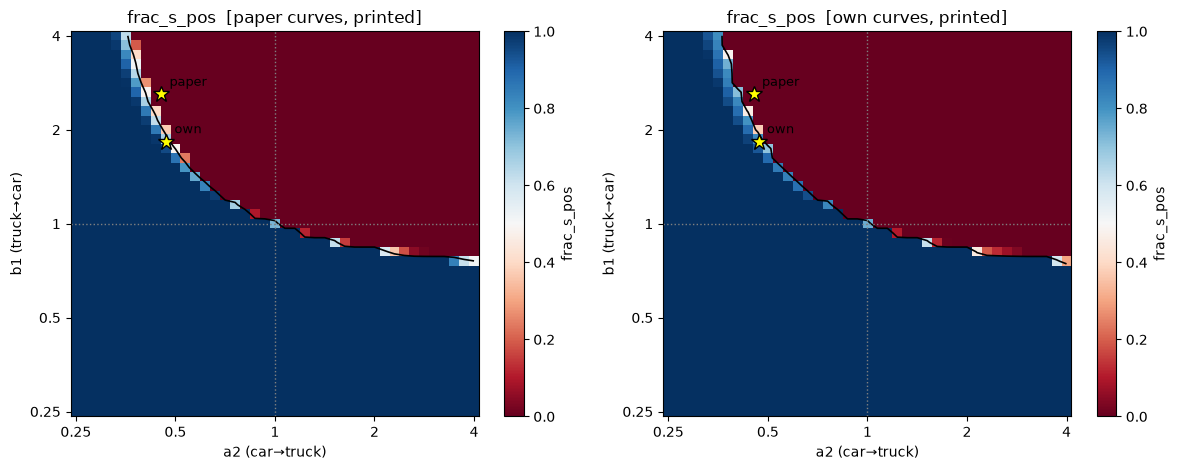

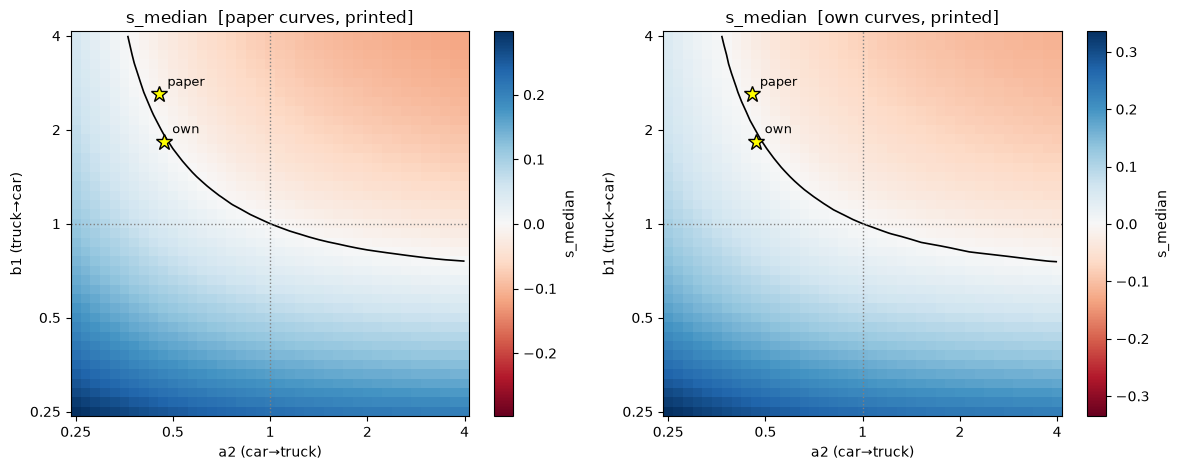

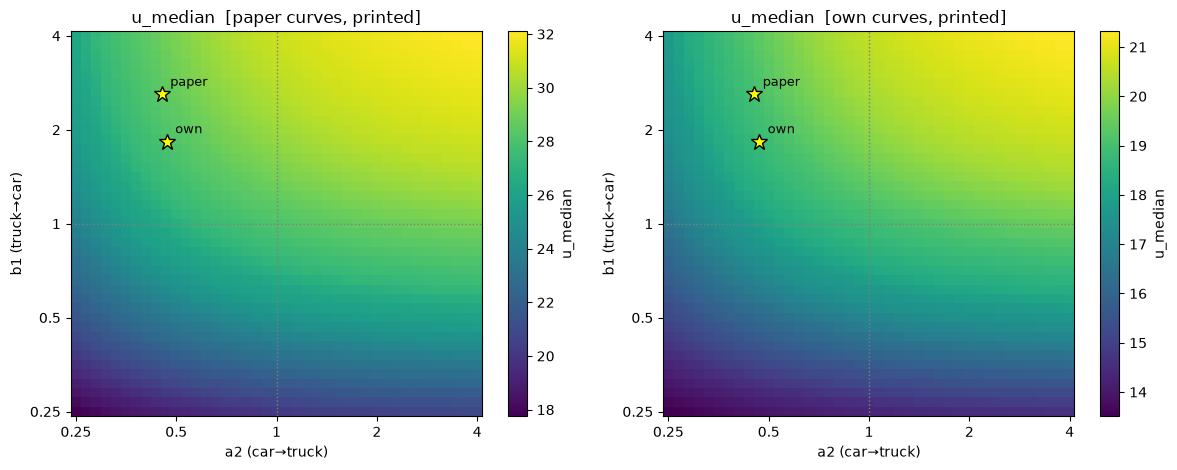

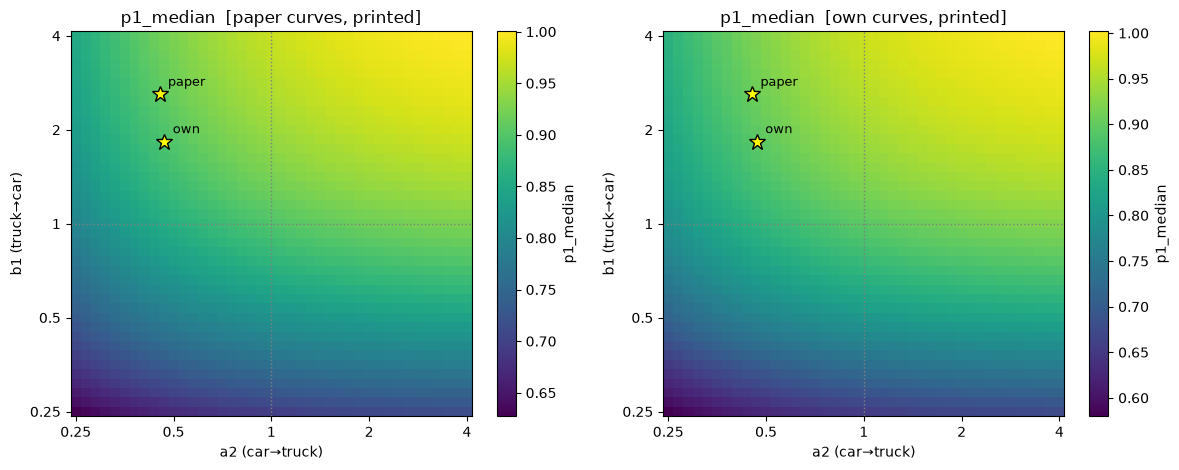

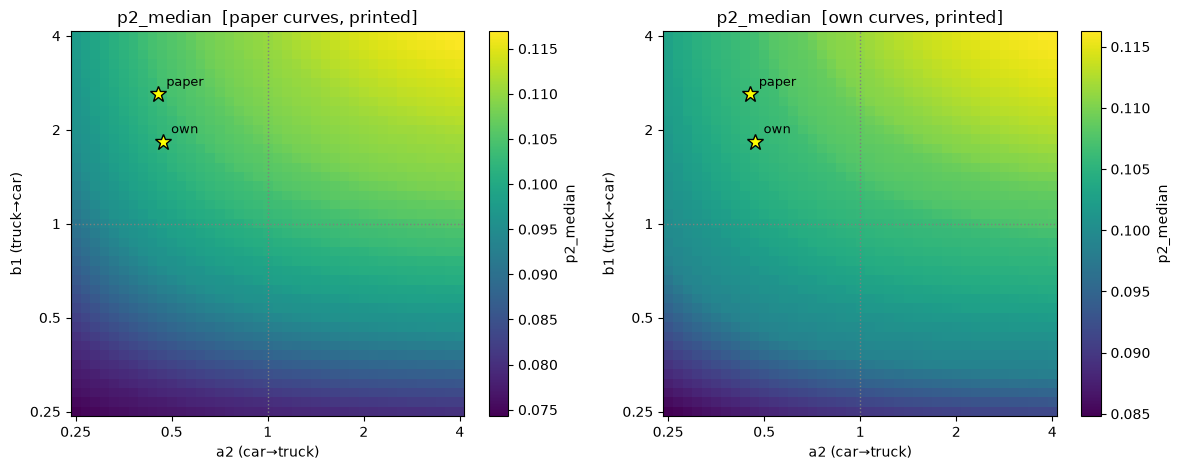

In [6]:
for col, center, cmap in [('frac_s_pos', 0.5, 'RdBu'), ('s_median', 0.0, 'RdBu'),
                         ('u_median', None, 'viridis'),
                         ('p1_median', None, 'viridis'), ('p2_median', None, 'viridis')]:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, (name, df) in zip(axs, sweeps.items()):
        plot_sweep(df, col, ax=ax, marks=marks, center=center, cmap=cmap,
                   title=f'{col}  [{name} curves, printed]')
    fig.tight_layout()
    plt.show()

inverted の値を見たいときは、printed の図で (1/a2, 1/b1) の位置を読む。例: 論文値 (0.4528, 2.5996) の inverted ⇔ printed の (2.208, 0.385)。

### (rho1, rho2) 平面上の s の地図
u*, p*, s は (rho1, rho2) とパラメータだけで決まるので、架空の密度格子で計算する。
黒点 = 観測スナップショット（両クラスがいるもの）。点の外は名目速度関数の外挿。
黒の太線 = s=0、灰色の細線 = u* の等高線(km/h)。

各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件
1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 2,130件）


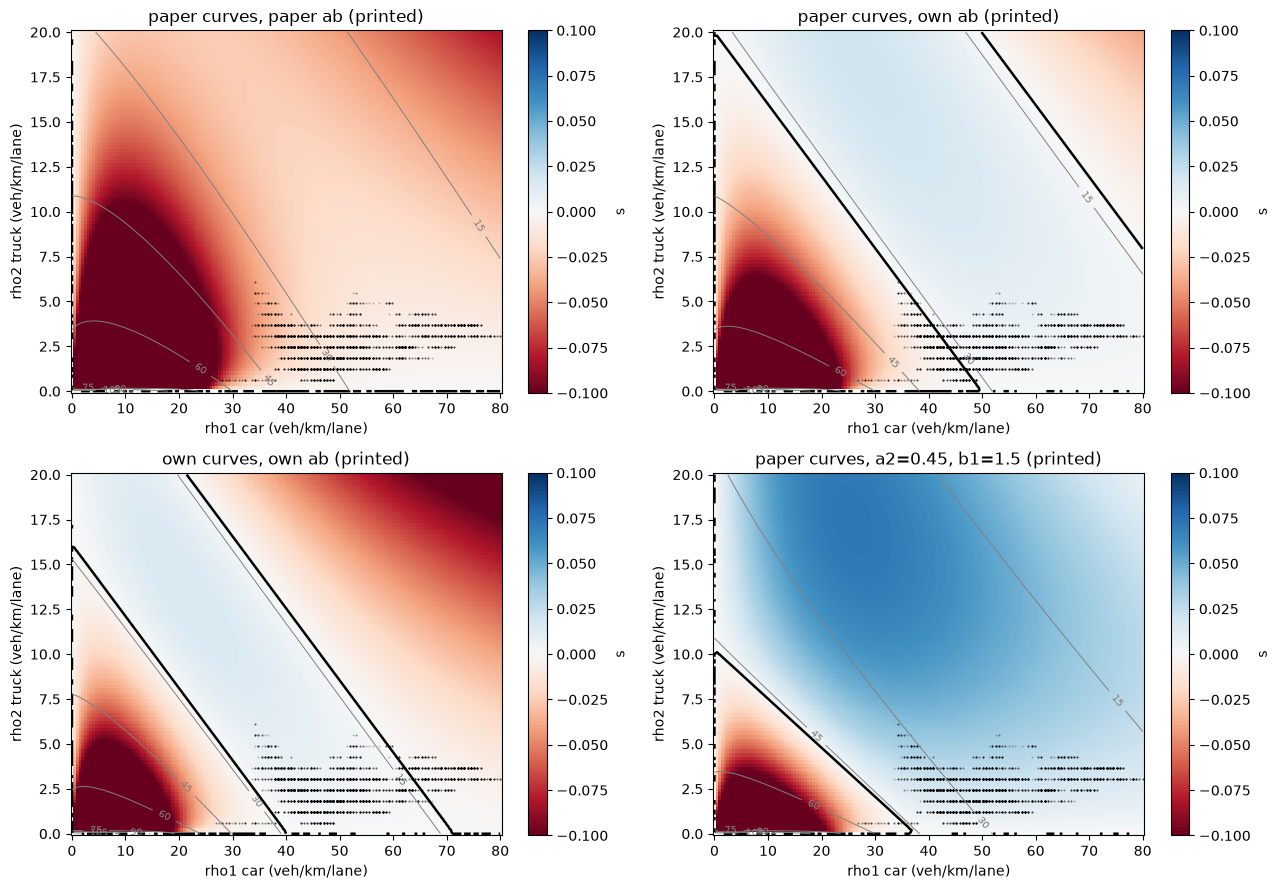

In [7]:
states_paper = pipeline_step3(data, *params['paper'], 1.0, 1.0, 'printed',
                             skip_sec_warmup=SKIP_WARMUP, skip_sec_cooldown=SKIP_COOLDOWN)
cases = [('paper', 'paper ab', marks['paper']),
         ('paper', 'own ab', marks['own']),
         ('own', 'own ab', marks['own']),
         ('paper', 'a2=0.45, b1=1.5', (0.45, 1.5))]
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
for ax, (curve, label, (a2, b1)) in zip(axs.flat, cases):
    m = surplus_map(*params[curve], a2, b1, 'printed', rho1_max=80, rho2_max=20)
    plot_surplus_map(m, states=states_paper, ax=ax, smax=0.1,
                     title=f'{curve} curves, {label} (printed)')
fig.tight_layout()
plt.show()